## Campaign Locations on the Drone Orthomosaic

The two measurement campaigns plotted on the high-resolution drone photo (07-10-2026), with the GPS-measured sensor positions.

1. **SSC campaign (29-09-2026)**, `Pruebas_DELFT_20260929.txt`
    - GPS0001 is the west flagpole
    - GPS0002 is the measurement pyramid (sensor)
    - GPS0003 is the east flagpole
    - GPS0004 is the cooperating flagpole
    - GPS0005 is the beach
2. **Flux campaign (02-10-2026)**, `Pruebas_DELFT_20261002.txt`
    - GPS0001 is the eastern end of the measurement frame (sensor)
    - GPS0002 is the western end of the measurement frame (sensor)
    - GPS0003 is the flagpole at the instruments
    - GPS0004 is the flagpole more in the port
    - GPS0005 is the flagpole more towards the sea

The drone photo and the GPS data are both in UTM zone 15N (EPSG:32615), so the photo can be plotted directly in easting/northing.
The SSC site lies just east of the area flown by the drone, so a satellite image is plotted underneath the drone photo to fill the gaps.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import contextily as ctx
import rasterio
from rasterio.windows import from_bounds
from rasterio.enums import Resampling

**1 Settings**

In [2]:
DRONE_TIF = r"C:\Users\apper\MDP_CameraLocalRuns\Drone footage\20261007_Canal_transparent_mosaic_group1 (1).tif"
GPS_CRS = "EPSG:32615"

OVERVIEW_PIXEL_M = 0.25   # resolution of the overview background [m] (smaller = sharper, but slower)
DETAIL_PIXEL_M = 0.02     # resolution of the zoomed-in backgrounds [m] (the drone photo itself is ~0.019 m)

**1.1 Loading the GPS points**

In [3]:
columns = [
    "point_id",
    "date",
    "time",
    "easting",
    "northing",
    "ellipsoidal_height",
    "geoid_separation",
    "cq_3d",
]


def load_gps_points(file_path):
    """Only the discrete GPSXXXX points (flags and sensor) of a campaign file."""
    gps = pd.read_csv(file_path, sep=r"\s+", skiprows=1, names=columns)
    gps["datetime"] = pd.to_datetime(gps["date"] + " " + gps["time"], format="%m/%d/%Y %H:%M:%S")
    gps["datetime"] = gps["datetime"] - pd.Timedelta(hours=1)
    gps["elevation"] = gps["ellipsoidal_height"] - gps["geoid_separation"]
    return gps[gps["point_id"].str.match(r"^GPS\d")].reset_index(drop=True)


# For each campaign: what every GPS point is, and whether it is a flag or (part of) the sensor
campaigns = {
    "SSC campaign (29-09-2026)": {
        "file": "Pruebas_DELFT_20260929.txt",
        "points": {
            "GPS0001": ("West flagpole", "flag"),
            "GPS0002": ("Measurement pyramid", "sensor"),
            "GPS0003": ("East flagpole", "flag"),
            "GPS0004": ("Cooperating flagpole", "flag"),
            "GPS0005": ("Beach", "other"),
        },
    },
    "Flux campaign (02-10-2026)": {
        "file": "Pruebas_DELFT_20261002.txt",
        "points": {
            "GPS0001": ("Frame east end", "sensor"),
            "GPS0002": ("Frame west end", "sensor"),
            "GPS0003": ("Flagpole at instruments", "flag"),
            "GPS0004": ("Flagpole port side", "flag"),
            "GPS0005": ("Flagpole sea side", "flag"),
        },
    },
}

for name, campaign in campaigns.items():
    points = load_gps_points(campaign["file"])
    points["label"] = points["point_id"].map(lambda p: campaign["points"][p][0])
    points["kind"] = points["point_id"].map(lambda p: campaign["points"][p][1])
    campaign["gps"] = points
    print(name)
    display(points[["point_id", "label", "kind", "easting", "northing", "elevation"]])

SSC campaign (29-09-2026)


,point_id,label,kind,easting,northing,elevation
0,GPS0001,West flagpole,flag,806688.1680,2.343461e+06,-1.3292
1,GPS0002,Measurement pyramid,sensor,806687.4266,2.343459e+06,-1.3249
2,GPS0003,East flagpole,flag,806697.2479,2.343461e+06,-1.3723
3,GPS0004,Cooperating flagpole,flag,806687.4149,2.343452e+06,-1.4172
4,GPS0005,Beach,other,806680.4073,2.343383e+06,-0.3969


Flux campaign (02-10-2026)


,point_id,label,kind,easting,northing,elevation
0,GPS0001,Frame east end,sensor,806486.1892,2.343121e+06,-1.5066
1,GPS0002,Frame west end,sensor,806485.3477,2.343120e+06,-1.5166
2,GPS0003,Flagpole at instruments,flag,806484.9354,2.343120e+06,-1.7211
3,GPS0004,Flagpole port side,flag,806485.4415,2.343117e+06,-1.5111
4,GPS0005,Flagpole sea side,flag,806483.5200,2.343123e+06,-1.5649


**1.2 Loading the drone photo**

The full photo is ~700 MB, so for the overview it is read at a lower resolution and saved next to this notebook (delete the `.npz` file if the photo or `OVERVIEW_PIXEL_M` changes). For the zoomed-in plots only the small area around each site is read, at full resolution.

In [4]:
def drone_photo(tif, pixel_m, bounds=None):
    """Drone photo (RGBA) and its extent (left, right, bottom, top) in UTM metres.
    bounds = (left, bottom, right, top) reads only that area; None reads the whole photo."""
    with rasterio.open(tif) as src:
        if bounds is None:
            window = None
            left, bottom, right, top = src.bounds
        else:
            # Clip the requested area to the photo; outside it there is nothing to read
            left, bottom = max(bounds[0], src.bounds.left), max(bounds[1], src.bounds.bottom)
            right, top = min(bounds[2], src.bounds.right), min(bounds[3], src.bounds.top)
            if left >= right or bottom >= top:
                return None, None
            window = from_bounds(left, bottom, right, top, src.transform)
        rows, cols = int((top - bottom) / pixel_m), int((right - left) / pixel_m)
        img = src.read(window=window, out_shape=(src.count, rows, cols), resampling=Resampling.average)
    img = np.moveaxis(img, 0, -1)       # (bands, rows, cols) -> (rows, cols, bands) for imshow
    return img, (left, right, bottom, top)


def drone_overview(tif, pixel_m):
    """The whole drone photo at pixel_m resolution, cached on disk because reading it takes a while."""
    cache = f"drone_overview_{pixel_m}m.npz"
    if os.path.exists(cache):
        saved = np.load(cache)
        return saved["img"], tuple(saved["extent"])
    img, extent = drone_photo(tif, pixel_m)
    np.savez_compressed(cache, img=img, extent=extent)
    return img, extent


overview_img, overview_extent = drone_overview(DRONE_TIF, OVERVIEW_PIXEL_M)
print("drone photo extent (left, right, bottom, top):", overview_extent)

drone photo extent (left, right, bottom, top): (np.float64(806345.1406800001), np.float64(806669.1350100001), np.float64(2342864.29759), np.float64(2343443.8955200003))


**1.3 Plotting helpers**

In [5]:
def add_background(ax, bounds, drone_img, drone_extent, zoom):
    """Satellite image underneath, drone photo on top (transparent outside the flown area)."""
    ax.set_xlim(bounds[0], bounds[2])
    ax.set_ylim(bounds[1], bounds[3])
    try:
        ctx.add_basemap(ax, source=ctx.providers.Esri.WorldImagery, crs=GPS_CRS,
                        zoom=zoom, reset_extent=False, attribution=False)
    except Exception as err:
        print("satellite basemap failed:", err)
    if drone_img is not None:
        ax.imshow(drone_img, extent=drone_extent, zorder=1)
    # imshow changes the axis limits, so set them again
    ax.set_xlim(bounds[0], bounds[2])
    ax.set_ylim(bounds[1], bounds[3])


def plot_sensor(ax, points):
    """Sensor position(s) of one campaign, in white."""
    sensor = points[points["kind"] == "sensor"]
    # The flux sensor is a frame: draw it as a line between its two ends
    if len(sensor) == 2:
        ax.plot(sensor["easting"], sensor["northing"], color="white", linewidth=3, zorder=4)
    ax.scatter(sensor["easting"], sensor["northing"], marker="*", color="white", s=320,
               edgecolors="black", linewidths=1, zorder=5)


def bounds_around(points, padding):
    """Square area around the points, with padding in metres."""
    xc = (points["easting"].min() + points["easting"].max()) / 2
    yc = (points["northing"].min() + points["northing"].max()) / 2
    half = max(np.ptp(points["easting"]), np.ptp(points["northing"])) / 2 + padding
    return (xc - half, yc - half, xc + half, yc + half)

### 2 Overview of both campaign locations

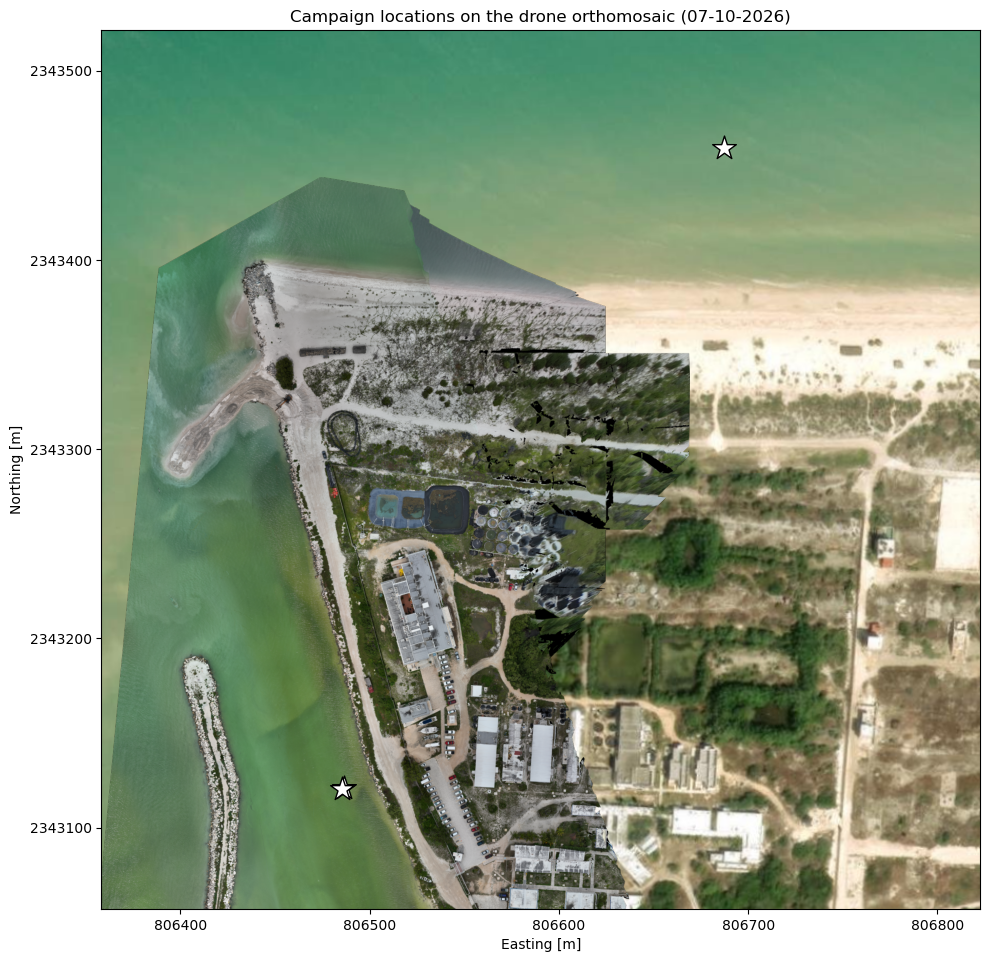

In [6]:
all_points = pd.concat([c["gps"] for c in campaigns.values()])
bounds = bounds_around(all_points, padding=60)

fig, ax = plt.subplots(figsize=(10, 12))
add_background(ax, bounds, overview_img, overview_extent, zoom=18)

for campaign in campaigns.values():
    plot_sensor(ax, campaign["gps"])

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Easting [m]")
ax.set_ylabel("Northing [m]")
ax.ticklabel_format(useOffset=False, style="plain")
ax.set_title("Campaign locations on the drone orthomosaic (07-10-2026)")
plt.tight_layout()
plt.savefig("campaign_locations_overview.png", dpi=200, bbox_inches="tight")
plt.show()

### 3 Detailed view per campaign

Zoomed in around the sensor of each campaign.

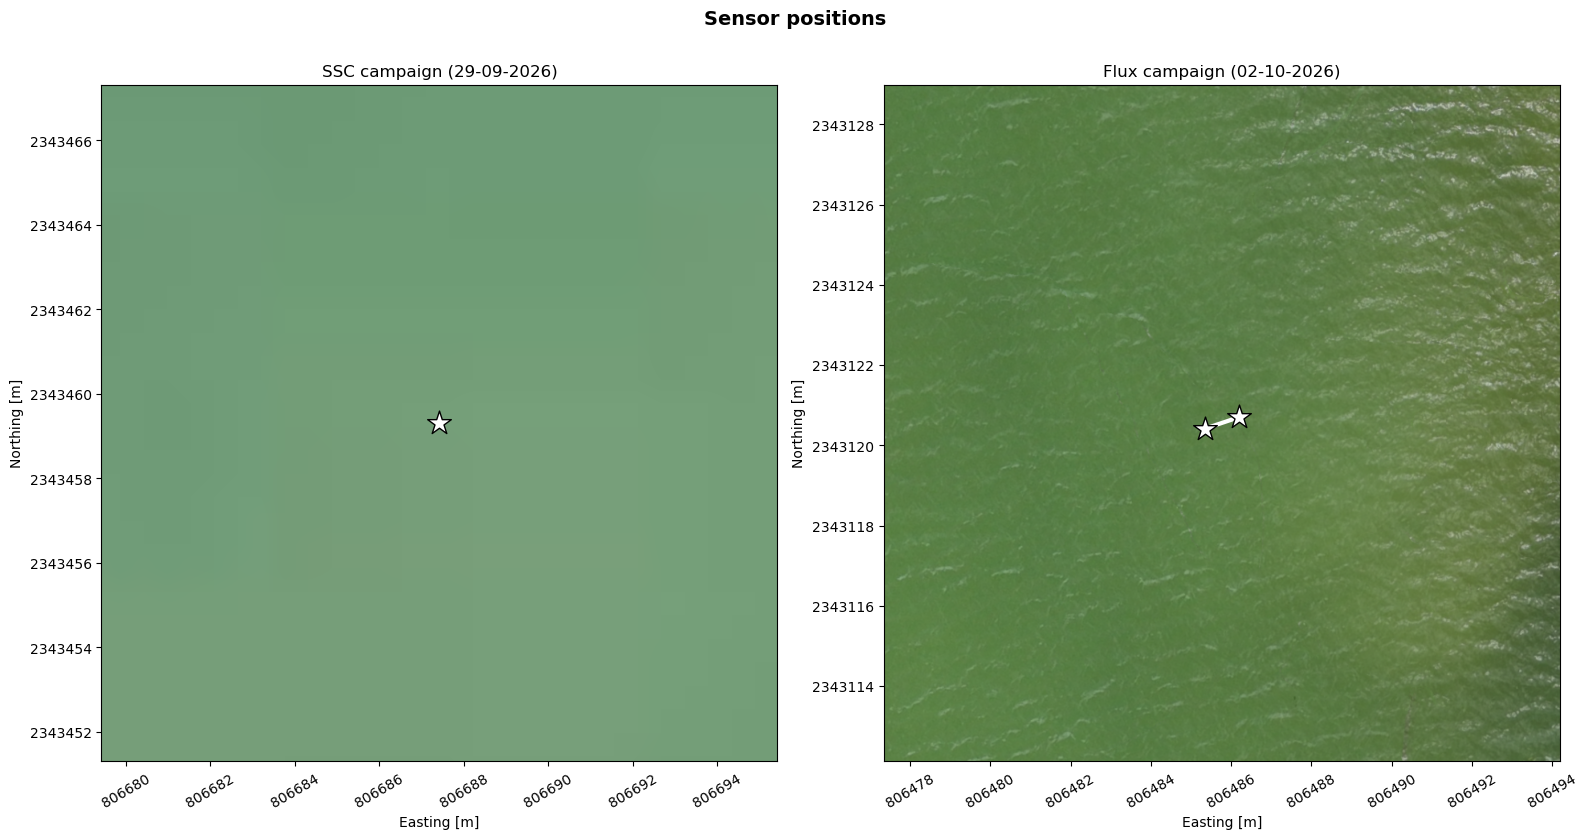

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8.5))

for ax, (name, campaign) in zip(axes, campaigns.items()):
    points = campaign["gps"]
    bounds = bounds_around(points[points["kind"] == "sensor"], padding=8)

    img, extent = drone_photo(DRONE_TIF, DETAIL_PIXEL_M, bounds)
    add_background(ax, bounds, img, extent, zoom=18)
    plot_sensor(ax, points)

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Easting [m]")
    ax.set_ylabel("Northing [m]")
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.tick_params(axis="x", labelrotation=30)
    ax.set_title(name)

fig.suptitle("Sensor positions", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("campaign_locations_detail.png", dpi=200, bbox_inches="tight")
plt.show()

**3.1 Distances between flags and sensor**

In [8]:
for name, campaign in campaigns.items():
    points = campaign["gps"].set_index("point_id")
    sensor = points[points["kind"] == "sensor"][["easting", "northing"]].mean()
    print(name)
    for point_id, p in points[points["kind"] == "flag"].iterrows():
        distance = np.hypot(p["easting"] - sensor["easting"], p["northing"] - sensor["northing"])
        print(f"    {p['label']:<25} {distance:6.2f} m from the sensor")
    print()

SSC campaign (29-09-2026)
    West flagpole               1.57 m from the sensor
    East flagpole              10.05 m from the sensor
    Cooperating flagpole        7.51 m from the sensor

Flux campaign (02-10-2026)
    Flagpole at instruments     0.90 m from the sensor
    Flagpole port side          3.43 m from the sensor
    Flagpole sea side           3.12 m from the sensor

